# Nettoyage et analyse exploratoire de l’occupation du sol

## Objectif
Préparer le jeu `Data_Yakro_New.csv`, contrôler sa qualité et décrire les observations avant la modélisation.


## 1. Importation et aperçu des données


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

from shapely.wkt import loads
import rasterio
from rasterio.plot import show


In [5]:
data=pd.read_csv('Data_Yakro_New.csv')
data.head()

,id,Classes1,geometry,class_name,B1,B2,B3,B4,B5,B6,...,EVI,NDRE,SAVI,NDMI,NDWI,NDWI2,MSI,NDBI,BSI,BI
0,0,3,POINT (226144.65598592497 753082.887017474),Rubber and Other Crops,0.1231,0.1090,0.0979,0.1162,0.1739,0.2023,...,0.100770,0.131802,0.196642,0.031392,-0.396795,0.031392,0.939122,-0.031392,-0.009928,0.146936
1,1,3,POINT (244896.1592880598 760596.3456779018),Rubber and Other Crops,0.1148,0.1007,0.0833,0.1013,0.1755,0.2105,...,0.132572,0.153809,0.246252,0.171316,-0.483569,0.171316,0.707477,-0.171316,-0.113658,0.145435
2,2,1,POINT (234575.58289979704 784710.4423564736),Forest,0.1067,0.0879,0.0698,0.0922,0.1603,0.1894,...,0.125394,0.143239,0.226460,0.144768,-0.507929,0.144768,0.747075,-0.144768,-0.089924,0.129279
3,3,3,POINT (262685.5122421682 754346.432833524),Rubber and Other Crops,0.1193,0.1047,0.0892,0.1063,0.1744,0.2068,...,0.119077,0.143418,0.226135,0.138943,-0.445961,0.138943,0.756010,-0.138943,-0.089061,0.145271
4,4,2,POINT (230657.7821066108 782973.1019210984),Coffee and Cocoa,0.1136,0.1010,0.0813,0.1053,0.1860,0.2198,...,0.141887,0.157227,0.261589,0.155133,-0.517076,0.155133,0.731399,-0.155133,-0.099152,0.152584


In [6]:
#taille du jeu de données  et verification du types des variables 
data.shape
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1000 non-null   int64  
 1   Classes1    1000 non-null   int64  
 2   geometry    1000 non-null   str    
 3   class_name  1000 non-null   str    
 4   B1          1000 non-null   float64
 5   B2          1000 non-null   float64
 6   B3          1000 non-null   float64
 7   B4          1000 non-null   float64
 8   B5          1000 non-null   float64
 9   B6          1000 non-null   float64
 10  B7          1000 non-null   float64
 11  B8          1000 non-null   float64
 12  B9          1000 non-null   float64
 13  B10         1000 non-null   float64
 14  NDVI        1000 non-null   float64
 15  EVI         1000 non-null   float64
 16  NDRE        1000 non-null   float64
 17  SAVI        1000 non-null   float64
 18  NDMI        1000 non-null   float64
 19  NDWI        1000 non-null   float64
 20

Le jeu de données contient **1 000 observations et 25 variables**. La colonne `geometry`, qui indique la position spatiale des observations, est initialement stockée sous forme de texte. La classe d’occupation du sol est représentée de deux façons : par son nom dans `class_name` et par un code numérique dans `Classes1`. Nous conserverons ces deux colonnes pour comparer les représentations de la variable cible et évaluer leur effet sur les performances du modèle.


## 2. Nettoyage et préparation des données


### 2.1 Vérification des doublons


In [7]:
nombre_doublons = data.duplicated().sum()
data = data.drop_duplicates().copy()

# verification de l'unicité de la variable geometry egalement
data[data.duplicated(subset=['geometry'])]

print(f"Lignes dupliquées supprimées : {nombre_doublons}")
print(f"Dimensions apres dedoublonnage : {data.shape}")

Lignes dupliquées supprimées : 0
Dimensions apres dedoublonnage : (1000, 25)


nous constatons qu'il n'y pas de doublon de ligne

### 2.2 Préparation de la géométrie


In [8]:

#On s'assure que la colonne est bien lue comme du texte et on enlève les espaces superflus
data['geometry'] = data['geometry'].astype(str).str.strip()

# On convertit le texte WKT "POINT (X Y)" en véritable objet géométrique Shapely
data['geometry'] = data['geometry'].apply(loads)

#verification de premiere etape de la transformation de la variable geometry
print(f"Vérification 1 : {data['geometry'].dtype}")


 #On transforme le DataFrame Pandas en GeoDataFrame pour activer les fonctions spatiales
gdf = gpd.GeoDataFrame(data, geometry='geometry')

 #Vérification du type du jeu definitif
gdf.info()





Vérification 1 : object
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id          1000 non-null   int64   
 1   Classes1    1000 non-null   int64   
 2   geometry    1000 non-null   geometry
 3   class_name  1000 non-null   str     
 4   B1          1000 non-null   float64 
 5   B2          1000 non-null   float64 
 6   B3          1000 non-null   float64 
 7   B4          1000 non-null   float64 
 8   B5          1000 non-null   float64 
 9   B6          1000 non-null   float64 
 10  B7          1000 non-null   float64 
 11  B8          1000 non-null   float64 
 12  B9          1000 non-null   float64 
 13  B10         1000 non-null   float64 
 14  NDVI        1000 non-null   float64 
 15  EVI         1000 non-null   float64 
 16  NDRE        1000 non-null   float64 
 17  SAVI        1000 non-null   float64 
 18  NDMI        1000 

In [9]:
 #Afficher les valeurs distinctes avant nettoyage de la variable class_name
from pyparsing import col


display(gdf["class_name"].unique())



# convertir en catégorie
gdf["class_name"] = gdf["class_name"].astype("category")

gdf.info()


<StringArray>
[              'Rubber and Other Crops',
                               'Forest',
                     'Coffee and Cocoa',
                             'Savannas',
                             'Wetlands',
                         'Water Bodies',
 'Human Infrastructure and Settlements',
          'Bare Soil and Rock Outcrops']
Length: 8, dtype: str

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id          1000 non-null   int64   
 1   Classes1    1000 non-null   int64   
 2   geometry    1000 non-null   geometry
 3   class_name  1000 non-null   category
 4   B1          1000 non-null   float64 
 5   B2          1000 non-null   float64 
 6   B3          1000 non-null   float64 
 7   B4          1000 non-null   float64 
 8   B5          1000 non-null   float64 
 9   B6          1000 non-null   float64 
 10  B7          1000 non-null   float64 
 11  B8          1000 non-null   float64 
 12  B9          1000 non-null   float64 
 13  B10         1000 non-null   float64 
 14  NDVI        1000 non-null   float64 
 15  EVI         1000 non-null   float64 
 16  NDRE        1000 non-null   float64 
 17  SAVI        1000 non-null   float64 
 18  NDMI        1000 non-null   float64 
 19 

## 3. Statistiques descriptives et compréhension des indices


In [10]:

gdf.describe().T

,count,mean,std,min,25%,50%,75%,max
id,1000.0,499.500000,288.819436,0.000000,249.750000,499.500000,749.250000,999.000000
Classes1,1000.0,3.246000,1.391913,1.000000,3.000000,3.000000,3.000000,8.000000
B1,1000.0,0.119123,0.005182,0.106700,0.115200,0.119200,0.122425,0.147700
B2,1000.0,0.104436,0.007063,0.084500,0.100175,0.104100,0.108325,0.145500
B3,1000.0,0.092469,0.013826,0.068000,0.082975,0.090900,0.099900,0.183900
B4,1000.0,0.110509,0.014041,0.063400,0.103300,0.109300,0.117400,0.200600
B5,1000.0,0.168073,0.026774,0.059600,0.157875,0.172900,0.184800,0.229200
B6,1000.0,0.195944,0.035550,0.059200,0.181300,0.201950,0.218000,0.269700
B7,1000.0,0.192639,0.037236,0.051100,0.178400,0.197800,0.214725,0.282400
B8,1000.0,0.220675,0.042405,0.053200,0.204500,0.227550,0.246200,0.306000


 Le tableau ne présente pas de valeurs manquantes.on peut noter que plusieurs  indices comme le NDVI, l’EVI, le NDRE, le SAVI, le NDMI, le NDWI, le NDBI et le BSI  comportent des valeurs négatives. on va donc vérifier leur définition afin de savoir comment les traiter. on notera aussi que NDMI et NDWI2 ont exactement les mêmes statistiques, tandis que NDBI semble être leur opposé.  

## Que nous apprend la littérature ?

| Indice | Nature générale | Précautions d’interprétation |
|---|---|---|
| **NDVI** | Indicateur de la présence et de l’activité de la végétation (Rouse et al., 1974 ; Tucker, 1979). | Peut moins bien différencier des couverts végétaux denses et proches. |
| **EVI** | Indice de végétation conçu pour réduire certaines influences du sol et de l’atmosphère (Huete et al., 2002). | Son interprétation dépend de la formule effectivement utilisée dans le jeu de données. |
| **NDRE** | Indice utilisant la bande red edge, souvent mobilisé pour caractériser la végétation. | Ne constitue pas une mesure directe de la chlorophylle. |
| **SAVI** | Indice de végétation conçu pour limiter l’influence du sol, notamment lorsque le couvert végétal est clairsemé (Huete, 1988). | Son interprétation dépend du paramètre utilisé dans son calcul. |
| **NDMI** | Indice couramment utilisé pour étudier l’humidité de la végétation. | Vérifier les bandes utilisées : les indices portant des noms proches peuvent avoir des définitions différentes. |
| **NDWI** | Indice pouvant servir à mettre en évidence l’eau de surface (McFeeters, 1996). |  |
| **NDWI2** | Nom donné à une variante d’indice liée à l’eau dans certains jeux de données. |  |
| **MSI** | Indice généralement associé au stress hydrique de la végétation. |  |
| **NDBI** | Indice souvent utilisé pour repérer les surfaces bâties (Zha et al., 2003). | Peut réagir également aux sols nus ; il ne suffit pas seul à identifier le bâti. |
| **BSI** | Indice utilisé pour mettre en évidence les sols nus. |  |



| Indice | Plage indicative | Interprétation possible d’une valeur négative |
|---|---:|---|
| **NDVI** | −1 à 1 | Réflectance rouge supérieure au proche infrarouge ; cela peut correspondre à de l’eau ou à une surface peu végétalisée. |
| **EVI** | Généralement proche de −1 à 1 | Peut indiquer une faible activité végétale ou une surface non végétalisée. |
| **NDRE** | −1 à 1 | Peut correspondre à une végétation peu développée ou à une surface non végétalisée. |
| **SAVI** | Dépend du paramètre utilisé ; souvent proche de −1 à 1 | Peut refléter une faible couverture végétale ou l’influence du sol. |
| **NDMI** | −1 à 1 | Peut signaler une faible humidité de la végétation ou une surface sèche. |
| **NDWI** | −1 à 1 pour les variantes normalisées | Le sens dépend de la variante : une valeur négative ne signifie pas la même chose pour toutes les définitions du NDWI. |
| **NDBI** | −1 à 1 pour les variantes normalisées | Peut correspondre à une végétation ou à une surface non bâtie, selon les bandes utilisées. |
| **BSI** | Dépend de la formule | Peut indiquer une faible réponse relative des sols nus |
| **MSI** | Généralement positif | couramment calculé comme un rapport de réflectances. |
| **BI** | Pas de plage universelle | L’interprétation dépend de la définition de cet indice.|

la littérature en télédétection aussi note que beaucoup d’indices dérivés des mêmes bandes sont très corrélés, ce qui ajoute peu d’information.


### 3.1 Traitement des indices redondants


un retour dans le describe permet de noter que les plages sont respectés.
Nous supprimerons la variable redondante   NDWI2 et NDBI  


In [11]:
data=data.drop(["NDWI2","NDBI"], axis=1)
data.shape

(1000, 23)

## 4. Première analyse exploratoire


### 4.1 Répartition des classes


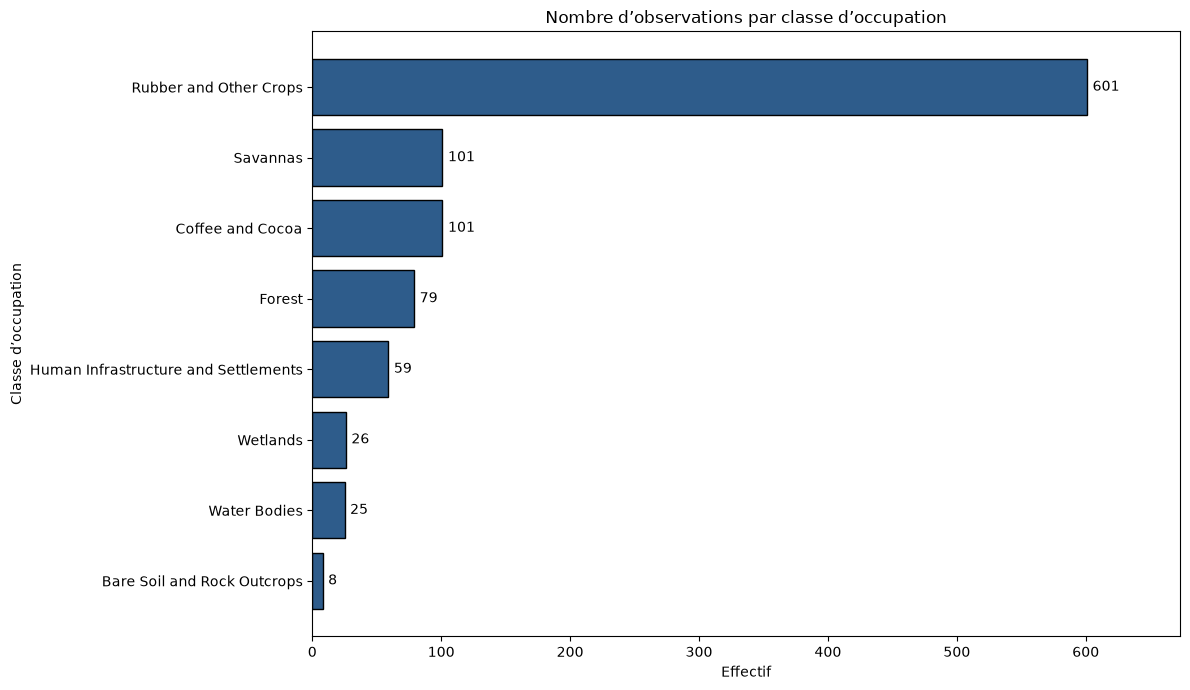

In [12]:

# Effectifs par classe d’occupation, du plus faible au plus élevé
effectifs = gdf["class_name"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    effectifs.index.astype(str),
    effectifs.values,
    color="#2e5c8b",
    edgecolor="black",
)

ax.set_title("Nombre d’observations par classe d’occupation")
ax.set_xlabel("Effectif")
ax.set_ylabel("Classe d’occupation")
ax.bar_label(bars, fmt="%d", padding=4)
ax.margins(x=0.12)

plt.tight_layout()
plt.show()



La figure présente la répartition des 1 000 observations selon huit classes d’occupation des sols. La classe Rubber and Other Crops domine largement avec 601 observations (60,1 %), suivie de Savannas et Coffee and Cocoa, qui comptent chacune 101 observations (10,1 %). Les autres classes sont moins représentées, notamment Wetlands (2,6 %), Water Bodies (2,5 %) et Bare Soil and Rock Outcrops (0,8 %).
Cette répartition révèle un déséquilibre important entre les classes. Lors de l’apprentissage du réseau de neurones artificiels (ANN), ce déséquilibre pourrait favoriser la classe majoritaire au détriment des classes minoritaires.

### 4.2 Répartition spatiale des observations


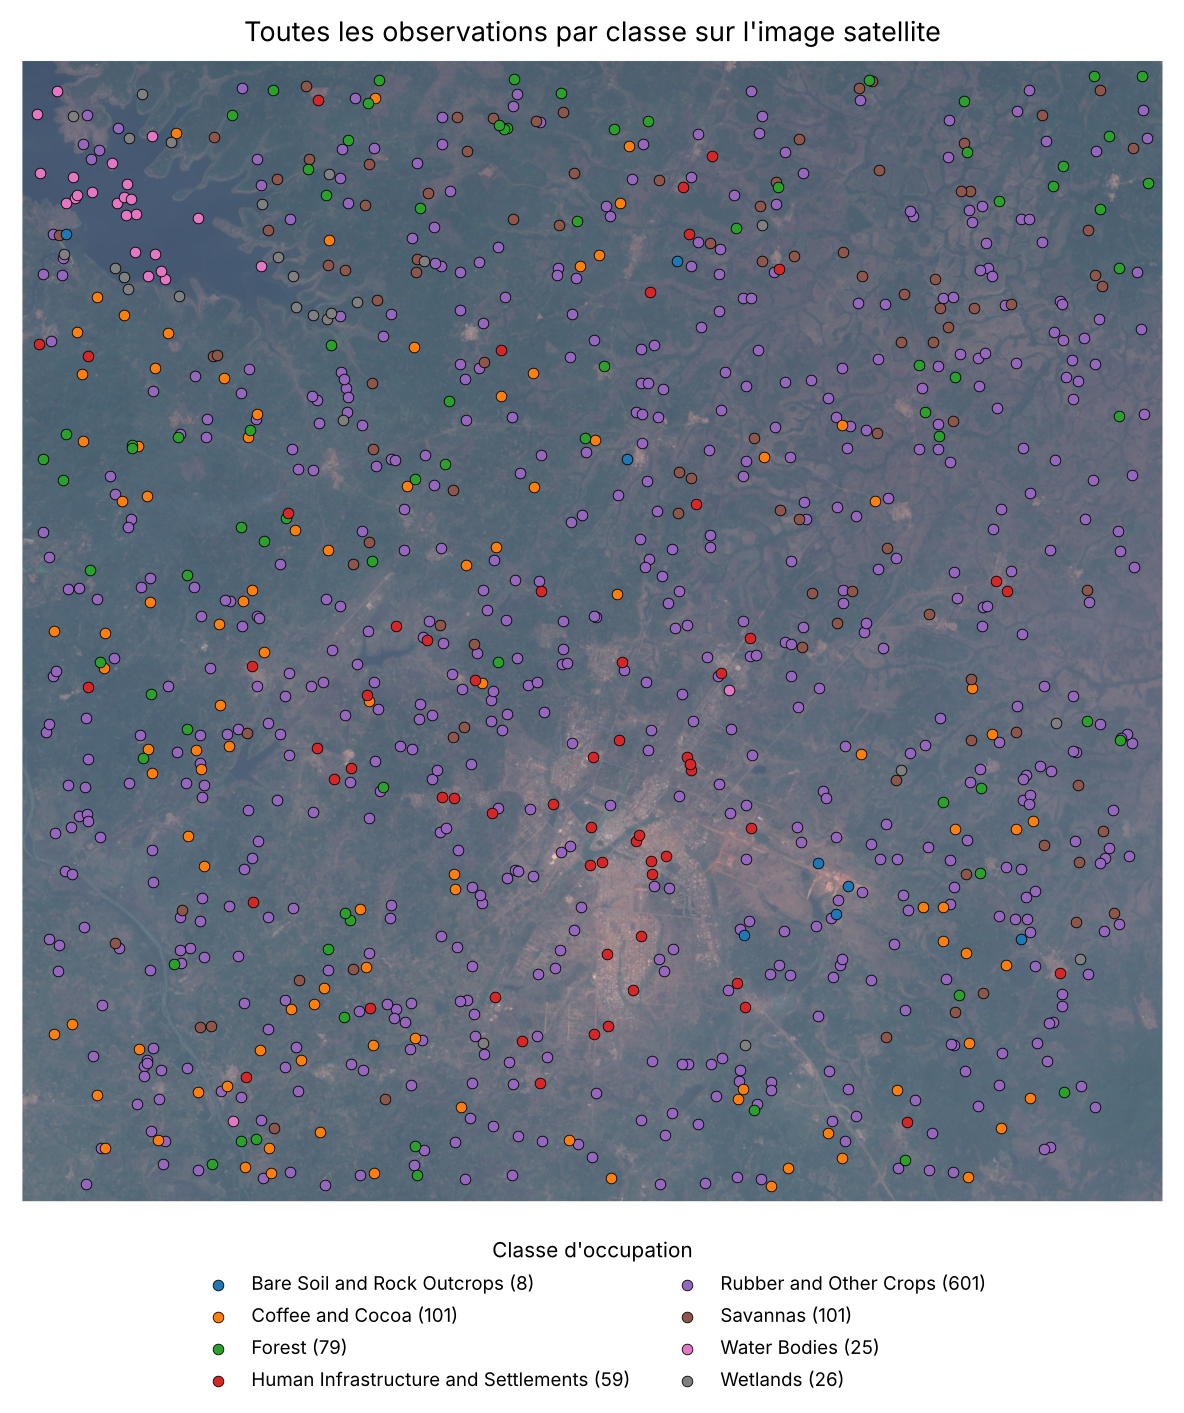

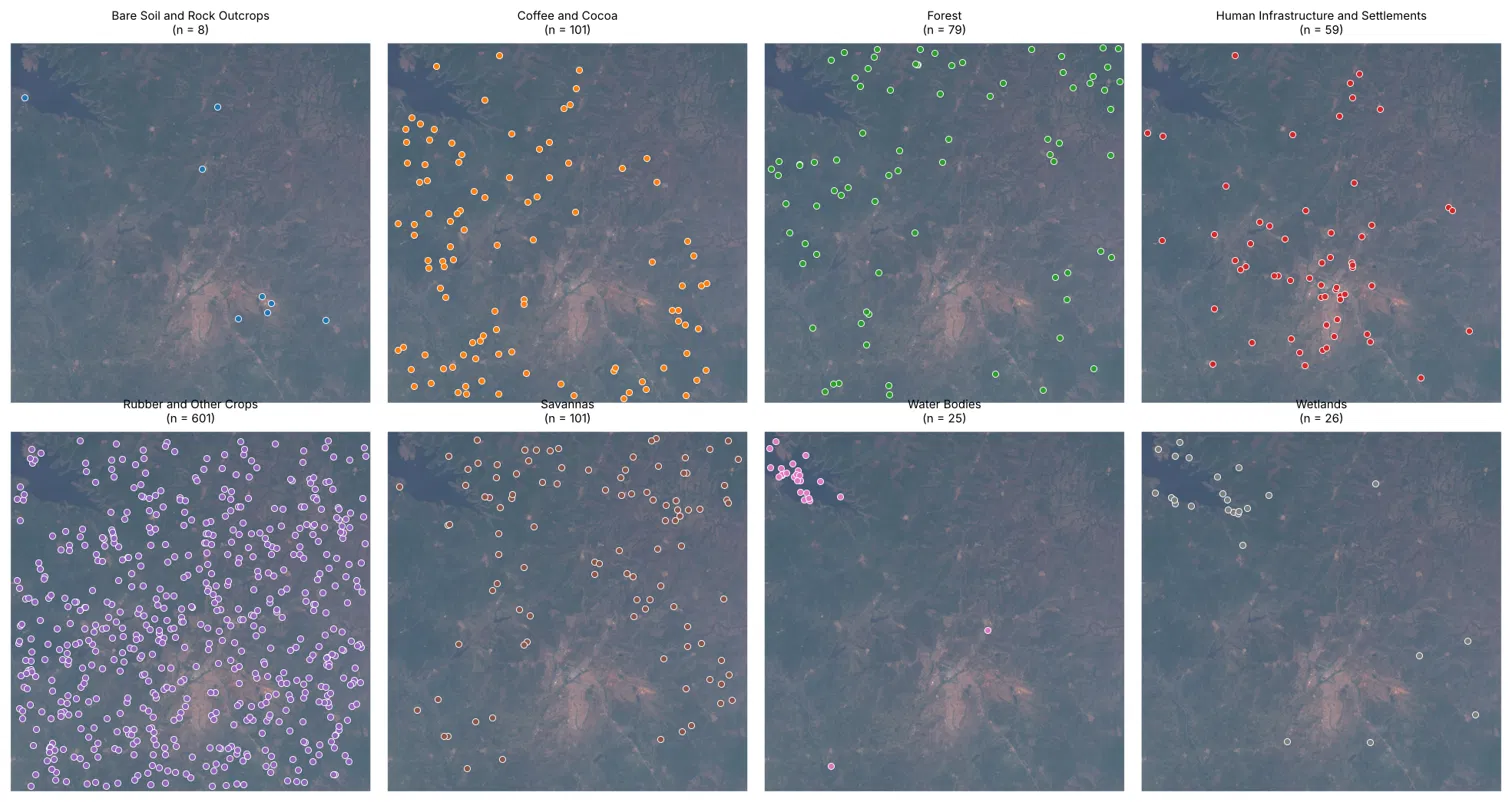

 Un zoom sur chaque classe confirme le commentaire precedent. la classe majoritaire, « Rubber and Other Crops » regroupe l’hévéa et d’autres cultures, ce qui, avec son poids, explique qu’on la retrouve un peu partout sur la zone. Pour les autres classes, chaque observation se situe globalement dans la zone attendue : l’eau et les zones humides autour du lac au nord-ouest, le bâti sur Yamoussoukro et ses axes, le sol nu dans la zone dénudée à l’est de la ville. Forest, Coffee and Cocoa et Savannas se regroupent par secteur (la forêt surtout au nord de la ville).

Deux observations étiquetées Water Bodies attirent l’attention, car elles se trouvent en terre ferme, loin du lac.

Les zones d’habitation ne correspondent pas toujours à du sol nu : plusieurs observations de la classe Human Infrastructure se trouvent en zone boisée, à proximité de cours d’eau et de plantations.On peut faire l’hypothèse que ces implantations profitent de la complémentarité des ressources (eau, terres cultivables, bois)

### 4.3 Exploration des valeurs extrêmes


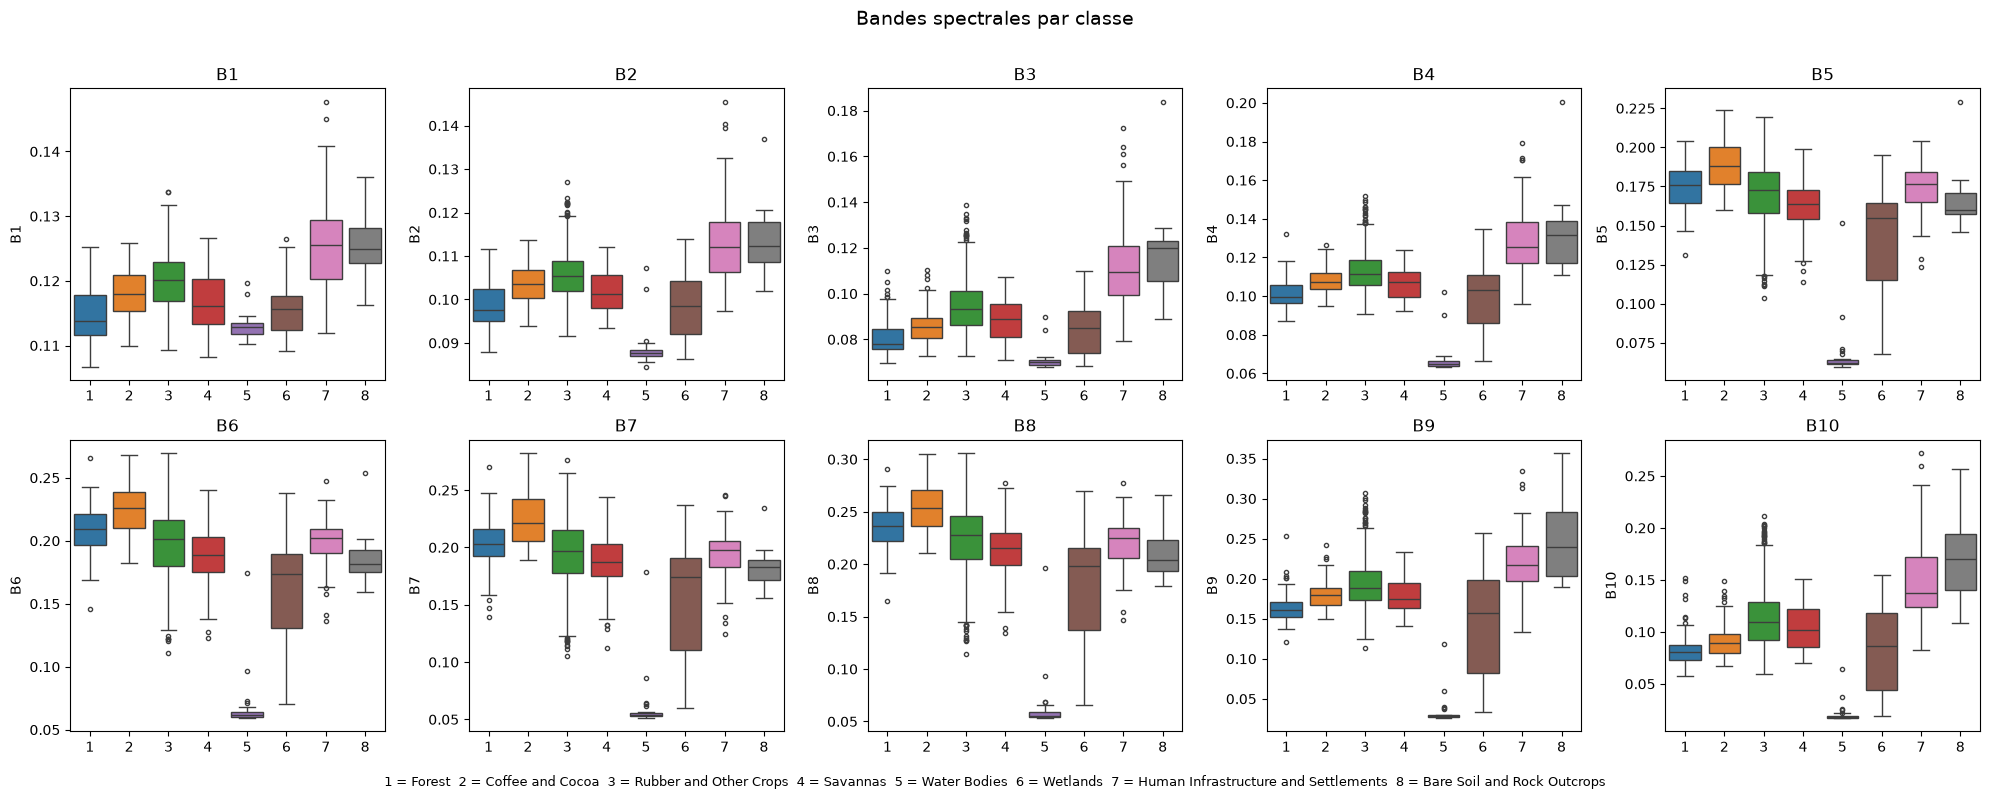

Classes non testées (n < 20 ) : ['Bare Soil and Rock Outcrops']
Categories (8, str): ['Bare Soil and Rock Outcrops', 'Coffee and Cocoa', 'Forest', 'Human Infrastructure and Settlements', 'Rubber and Other Crops', 'Savannas', 'Water Bodies', 'Wetlands']
gravite                               aucune  faible   moyenne   forte 
class_name                                                             
Coffee and Cocoa                          95        3         3       0
Forest                                    67        8         3       1
Human Infrastructure and Settlements      47        4         8       0
Rubber and Other Crops                   557       25        17       2
Savannas                                  95        4         2       0
Water Bodies                              19        1         1       4
Wetlands                                  25        1         0       0

Les  plus graves :
 id             class_name  n_bandes  n_bandes_extremes  n_indices          sen

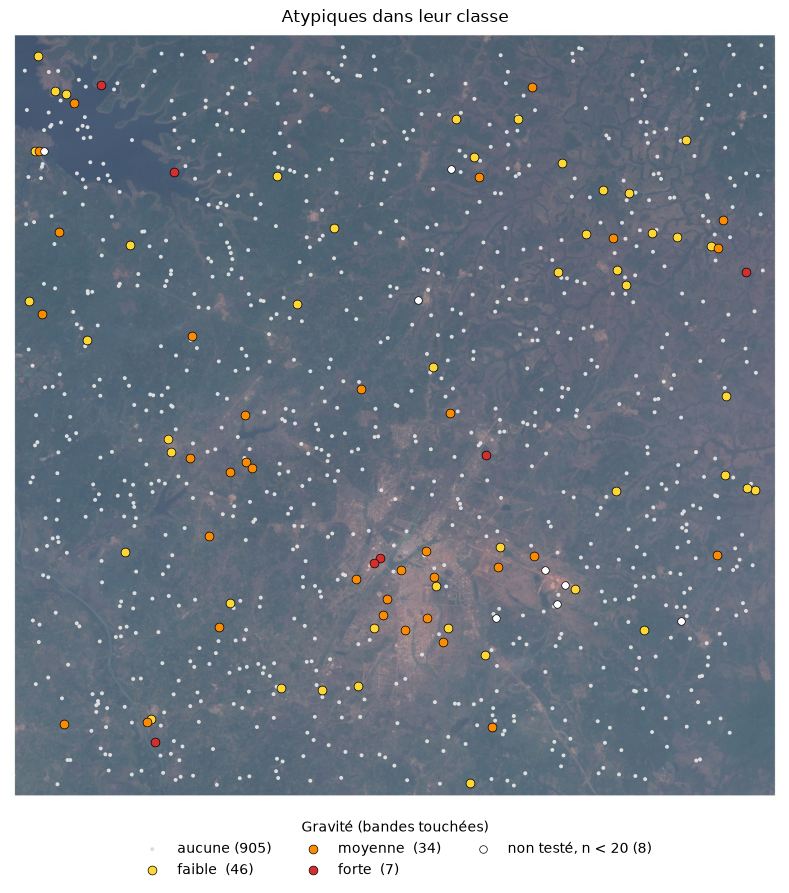

In [15]:
#valeur aberantes numeriques  a examiner 
import os


bandes = [f"B{i}" for i in range(1, 11)]
indices = ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "NDWI2", "MSI", "NDBI", "BSI", "BI"]
n_min = 20
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)


# 1. Boxplots par classe
## Une ligne par classe pour construire la légende des codes
codes = gdf[["Classes1", "class_name"]].drop_duplicates().sort_values("Classes1")
legende = "  ".join(f"{c} = {n}" for c, n in zip(codes["Classes1"], codes["class_name"]))
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for ax, b in zip(axs.ravel(), bandes):
    sns.boxplot(data=gdf, x="Classes1", y=b, hue="Classes1", palette="tab10", legend=False, ax=ax, fliersize=3)
    ax.set_title(b)
    ax.set_xlabel("")
fig.suptitle("Bandes spectrales par classe", fontsize=14)
fig.text(0.5, 0.01, legende, ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()
plt.close(fig)

analyse_atypiques = gdf.copy()
analyse_atypiques["x"] = analyse_atypiques.geometry.x
analyse_atypiques["y"] = analyse_atypiques.geometry.y
# 2. Atypiques dans la classe : bandes touchées, sens, gravité
analyse_atypiques["n_bandes"] = np.nan
analyse_atypiques["n_bandes_extremes"] = np.nan
analyse_atypiques["n_bandes_hautes"] = np.nan
analyse_atypiques["n_indices"] = np.nan
for classe, g in analyse_atypiques.groupby("class_name"):
    if len(g) < n_min:
        continue
    q1, q3 = g[bandes + indices].quantile(0.25), g[bandes + indices].quantile(0.75)
    iqr = q3 - q1
    bas = g[bandes + indices] < q1 - 1.5 * iqr
    haut = g[bandes + indices] > q3 + 1.5 * iqr
    extr = (g[bandes + indices] < q1 - 3 * iqr) | (g[bandes + indices] > q3 + 3 * iqr)
    analyse_atypiques.loc[g.index, "n_bandes"] = (bas[bandes] | haut[bandes]).sum(axis=1)
    analyse_atypiques.loc[g.index, "n_bandes_extremes"] = extr[bandes].sum(axis=1)
    analyse_atypiques.loc[g.index, "n_bandes_hautes"] = haut[bandes].sum(axis=1)
    analyse_atypiques.loc[g.index, "n_indices"] = (bas[indices] | haut[indices]).sum(axis=1)

analyse_atypiques["gravite"] = pd.cut(analyse_atypiques["n_bandes"], bins=[-1, 0, 2, 5, 10], labels=["aucune", "faible ", "moyenne ", "forte "])
analyse_atypiques["sens"] = np.where(analyse_atypiques["n_bandes"] == 0, "",
              np.where(analyse_atypiques["n_bandes_hautes"] == analyse_atypiques["n_bandes"], "toutes hautes",
              np.where(analyse_atypiques["n_bandes_hautes"] == 0, "toutes basses", "mixte")))

print("Classes non testées (n <", n_min, ") :", analyse_atypiques[analyse_atypiques["n_bandes"].isna()]["class_name"].unique())
print(pd.crosstab(analyse_atypiques["class_name"], analyse_atypiques["gravite"]))

suspects = analyse_atypiques[analyse_atypiques["n_bandes"] > 0].sort_values("n_bandes", ascending=False)
suspects[["id", "class_name", "n_bandes", "n_bandes_extremes", "n_indices", "sens", "gravite", "x", "y"]].to_csv(
    "atypiques_par_classe.csv", index=False)
print("\nLes  plus graves :")
print(suspects[["id", "class_name", "n_bandes", "n_bandes_extremes", "n_indices", "sens"]].head(10).to_string(index=False))

# 3. Contexte : carte (avec l'image satellite )
couleurs = {"aucune": "#dddddd", "faible ": "#fdd835", "moyenne ": "#fb8c00", "forte ": "#d32f2f"}
fig, ax = plt.subplots(figsize=(10, 10))
if os.path.exists("image_satellite.jpeg"):
    m = 0.02
    dx, dy = analyse_atypiques.x.max() - analyse_atypiques.x.min(), analyse_atypiques.y.max() - analyse_atypiques.y.min()
    ext = [analyse_atypiques.x.min() - m * dx, analyse_atypiques.x.max() + m * dx, analyse_atypiques.y.min() - m * dy, analyse_atypiques.y.max() + m * dy]
    ax.imshow(plt.imread("image_satellite.jpeg"), extent=ext, origin="upper")
for niveau, couleur in couleurs.items():
    d = analyse_atypiques[analyse_atypiques["gravite"] == niveau]
    ax.scatter(d.x, d.y, s=8 if niveau == "aucune" else 40, color=couleur, edgecolor="black" if niveau != "aucune" else "none",
               linewidth=0.5, label=f"{niveau} ({len(d)})")
d = analyse_atypiques[analyse_atypiques["n_bandes"].isna()]
ax.scatter(d.x, d.y, s=30, color="white", edgecolor="black", linewidth=0.5, label=f"non testé, n < {n_min} ({len(d)})")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(title="Gravité (bandes touchées)", loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
ax.set_title("Atypiques dans leur classe")
plt.show()
plt.close(fig)

analyse_atypiques.to_csv("donnees_avec_gravite.csv", index=False)

**interpretation.** Correspondance supposée des bandes avec Sentinel-2 (déduite de la cohérence des indices) :

| B1 | B2 | B3 | B4 | B5–B7 | B8 | B9 | B10 |
|---|---|---|---|---|---|---|---|
| Aérosols (443 nm) | Bleu | Vert | Rouge | Red edge | Proche infrarouge (PIR) | SWIR 1 (1 610 nm) | SWIR 2 (2 190 nm) |

- **Habitats (7) et sols nus (8)** ont les réflectances les plus élevées sur 6 bandes sur 10 : tout le visible (B1–B4) et le SWIR (B9–B10). Ce sont des surfaces sèches et sans chlorophylle : elles renvoient la lumière que la végétation absorbe, et l'absence d'eau les rend très réfléchissantes dans le SWIR. Les deux classes se ressemblent et ne se séparent vraiment que dans le PIR et le SWIR.
- **Les classes végétalisées** passent devant dans le red edge et le PIR (B5–B8), surtout Coffee and Cocoa (2) et Forest (1), mais leurs boîtes se chevauchent largement.
- **Water Bodies (5)** est la plus basse et la plus homogène ; **Wetlands (6)** est la plus dispersée, car elle mélange eau, sol saturé et végétation.

- **Rubber « toutes hautes » (12 obs.)** : compatibles avec Human Infrastructure et souvent Bare Soil. Elles sont pour la plupart dans Yamoussoukro ou à sa périphérie : ce sont des **pixels mixtes** (parcelles en bordure de ville ou partiellement dénudées).
- **Rubber et Savannas « toutes basses » (9 obs.)** : compatibles uniquement avec Wetlands, donc des parcelles plus humides (bas-fonds, bords de marigots).
- **Human Infrastructure « toutes hautes »** (centre-ville) : compatibles avec aucune autre classe, ce sont de vrais extrêmes du bâti (toitures, béton). Les « toutes basses » correspondent à un habitat sous couvert végétal.
- **Water Bodies du bord du lac (n° 19, 212, 990)** : c'est bien de l'eau (NDVI ≈ 0). La classe est si homogène que la moindre variation sort des bornes.
- **Trois cas douteux** à vérifier sur image haute résolution : n° 193 et 584 (Water Bodies), n° 732 (Forest).

Les pixels mixtes et les extrêmes réels sont **conservés** : ils représentent la réalité du terrain que le modèle devra apprendre.

#### 4.3.2 Vérification et correction des étiquettes douteuses

Les coordonnées sont en UTM zone 30N (EPSG:32630). On les convertit en latitude/longitude pour les vérifier sur Google Maps (vue satellite).

In [19]:
# Coordonnées GPS des trois observations douteuses
douteux = gdf[gdf["id"].isin([193, 584, 732])].set_crs(epsg=32630, allow_override=True).to_crs(epsg=4326)
display(douteux[["id", "class_name", "NDVI"]].assign(latitude=douteux.geometry.y.round(5),
                                                     longitude=douteux.geometry.x.round(5)))

# Corrections retenues après vérification (la 584 est conservée telle quelle)
corrections = {193: "Wetlands", 732: "Savannas"}
code_classe = dict(zip(gdf["class_name"].astype(str), gdf["Classes1"]))

for df in (data, gdf):
    for i, classe in corrections.items():
        df.loc[df["id"] == i, "class_name"] = classe
        df.loc[df["id"] == i, "Classes1"] = code_classe[classe]

gdf.loc[gdf["id"].isin(corrections), ["id", "class_name", "Classes1"]]

,id,class_name,NDVI,latitude,longitude
193,193,Water Bodies,0.315894,6.71549,-5.41557
584,584,Water Bodies,0.016857,6.87418,-5.23481
732,732,Forest,0.177857,6.97499,-5.09242


,id,class_name,Classes1
193,193,Wetlands,6
732,732,Savannas,4


| id | Étiquette d'origine | Constat sur l'image satellite | Décision |
|---|---|---|---|
| 193 | Water Bodies | Berge boisée du Bandama, en bordure immédiate du fleuve. Spectre de végétation très humide (NDVI = 0,32 ; SWIR plus bas que toutes les classes végétalisées), au centre du profil Wetlands | Ré-étiquetée **Wetlands** |
| 584 | Water Bodies | Au milieu d'un lac près de l'INP-HB Sud : c'est bien de l'eau | **Conservée** |
| 732 | Forest | Savane arbustive en bordure d'un massif forestier ; SWIR élevé et NDVI faible (0,18) | Ré-étiquetée **Savannas** |

L'image Google Maps n'a pas la même date que les données : ces décisions restent les plus cohérentes avec à la fois l'image et le spectre. Elles sont faites avant la séparation apprentissage / test.

### 4.4 Corrélation entre les indices construits


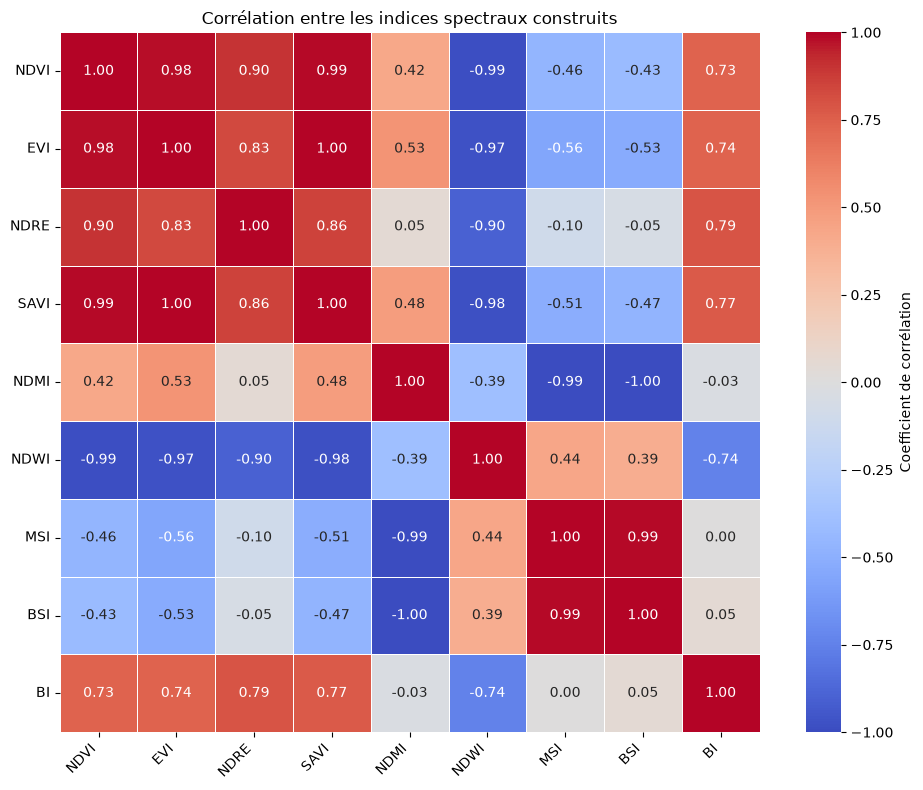

In [38]:
# Matrice de corrélation des indices spectraux construits
indicateurs_construits = [
    "NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"
]
correlations = data[indicateurs_construits].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coefficient de corrélation"},
    ax=ax,
)

ax.set_title("Corrélation entre les indices spectraux construits")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

La matrice montre que certains indices spectraux évoluent de manière très similaire. C’est notamment le cas du NDVI, de l’EVI et du SAVI, dont les corrélations sont très élevées (entre 0,98 et 1,00). Ces résultats suggèrent que ces indices fournissent en partie des informations similaires sur la végétation.
On observe également une forte relation négative entre le NDMI et le MSI (−0,99), ainsi qu’entre le NDMI et le BSI (−1,00). De même, le NDWI présente une forte corrélation négative avec le NDVI, l’EVI et le SAVI. Ces relations montrent que certains indices évoluent en sens opposé dans les données étudiées.
À l’inverse, la corrélation entre le NDRE et le NDMI est très faible (0,05), ce qui suggère qu’ils peuvent apporter des informations différentes. Ainsi, cette analyse nous permet de repérer les indices qui se ressemblent et ceux qui pourraient être complémentaires. Nous vérifierons leur utilité lors de la modélisation avant de décider quelles variables conserver pour la classification.

### 4.5 Signatures spectrales par classe

La signature spectrale est la courbe de réflectance d'une surface selon la longueur d'onde. On trace la médiane de chaque classe (robuste aux atypiques).

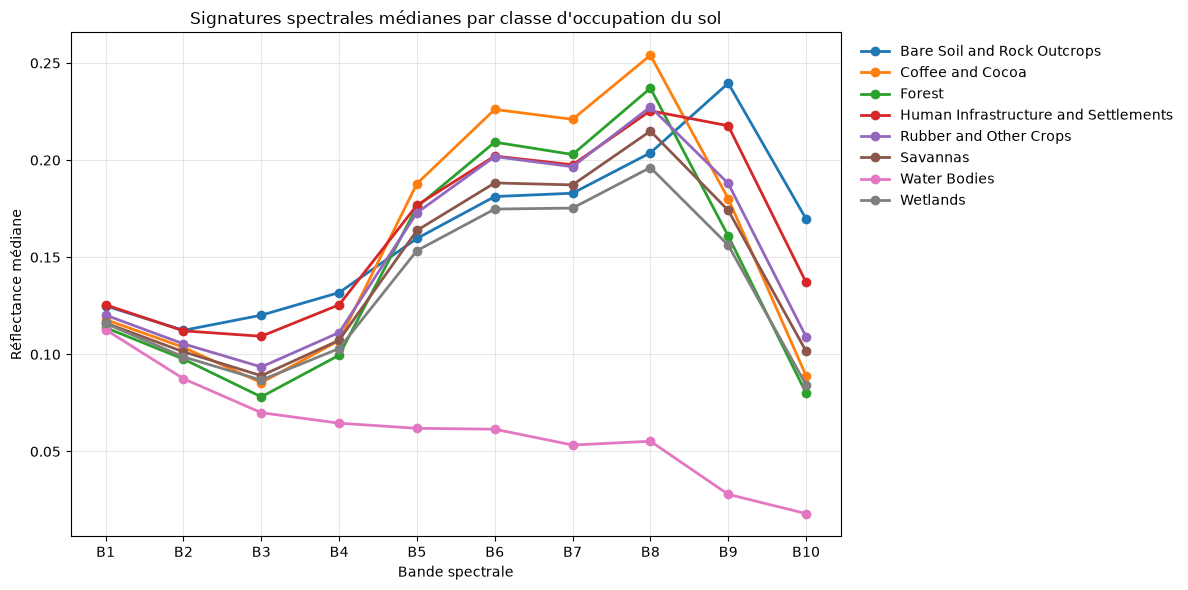

In [22]:
couleurs_classes = {
    "Forest": "#2ca02c", "Coffee and Cocoa": "#ff7f0e", "Rubber and Other Crops": "#9467bd",
    "Savannas": "#8c564b", "Water Bodies": "#e377c2", "Wetlands": "#7f7f7f",
    "Human Infrastructure and Settlements": "#d62728", "Bare Soil and Rock Outcrops": "#1f77b4",
}

mediane = gdf.groupby("class_name", observed=True)[bandes].median()

fig, ax = plt.subplots(figsize=(12, 6))
for classe, valeurs in mediane.iterrows():
    ax.plot(bandes, valeurs, marker="o", linewidth=2, color=couleurs_classes[classe], label=classe)

ax.set_xlabel("Bande spectrale")
ax.set_ylabel("Réflectance médiane")
ax.set_title("Signatures spectrales médianes par classe d'occupation du sol")
ax.grid(alpha=0.3)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

#interpretation    